# Paso 14 · Sistemas de dos estados: lazo interno y externo (con Python)

Notebook del **Paso 14**: cuando se mide también la velocidad, un lazo interno sobre $x_2$ encierra la parte *incierta* de la planta y deja un lazo externo fácil (solo una ganancia).

| Concepto matemático | Concepto de programación |
|---|---|
| $\dot x=Ax+Bu$, discretización ZOH | `signal.cont2discrete` con matrices |
| $P_1=T_2/s$ visto por el lazo externo | funciones que cierran un lazo interno |
| template más pequeño | `np.ptp` sobre las 221 plantas |
| realimentación de estados $u=-k_1x_1-k_2x_2$ | autovalores con `np.linalg.eigvals` |
| límite del lazo interno $K_{\max}k_vT_s<2$ | barrido de $k_v$ y radio espectral |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
from scipy import signal
from nbhelp import db, AZUL, NARANJA, TINTA, GRIS, VERDE
from qft import KS, AS, spec_ok, ratio, delta_db, WD, WS
Ts = 0.04; kv = 5.0; k = 4.0
nF, dF, _ = signal.cont2discrete(([1.2], [1, 1.2]), Ts, method="bilinear"); nF = nF.ravel()

## 1. La planta en variables de estado

$\dot x_1=x_2,\ \dot x_2=-a\,x_2+K\,u,\ y=x_1$. Con $K\in[1,5]$, $a\in[1,3]$: **toda** la incertidumbre está en la ecuación de $x_2$; $x_1$ es un integrador exacto. Si cerramos primero un lazo sobre $x_2$, lo incierto queda *dentro* del lazo y lo exacto ($1/s$) *fuera*.

## 2. Dos lazos: interno sobre $x_2$, externo sobre $x_1$

Lazo interno: $u=k_v(v_{ref}-x_2)$ ⇒ $T_2=\dfrac{Kk_v}{s+a+Kk_v}$. El lazo externo ve $P_1=T_2/s$.

In [3]:
P1c = lambda w, K, a, kvv: (K/(1j*w*(1j*w + a)) if kvv == 0 else (K*kvv/(1j*w + a + K*kvv))/(1j*w))

print(f"{'ω':>4} {'k_v':>5} {'dispersión módulo':>19} {'dispersión fase':>17}")
for w in (2.0,):
    for kvv in (0, 5, 20):
        z = np.array([P1c(w, K, a, kvv) for K in KS for a in AS]); rel = z/P1c(w, 1, 1, kvv)
        print(f"{w:>4g} {kvv:>5} {np.ptp(db(rel)):>16.1f} dB {np.ptp(np.degrees(np.angle(rel))):>14.1f}°")

   ω   k_v   dispersión módulo   dispersión fase
   2     0             18.1 dB           29.7°
   2     5              4.0 dB           14.3°
   2    20              1.2 dB            4.3°


En $\omega=2$ el template se reduce de **18.1 dB** (sin lazo interno) a **4.0 dB** con $k_v=5$ y **1.2 dB** con $k_v=20$. Un template pequeño exige poca ganancia al lazo externo (Paso 8): los bounds se relajan.

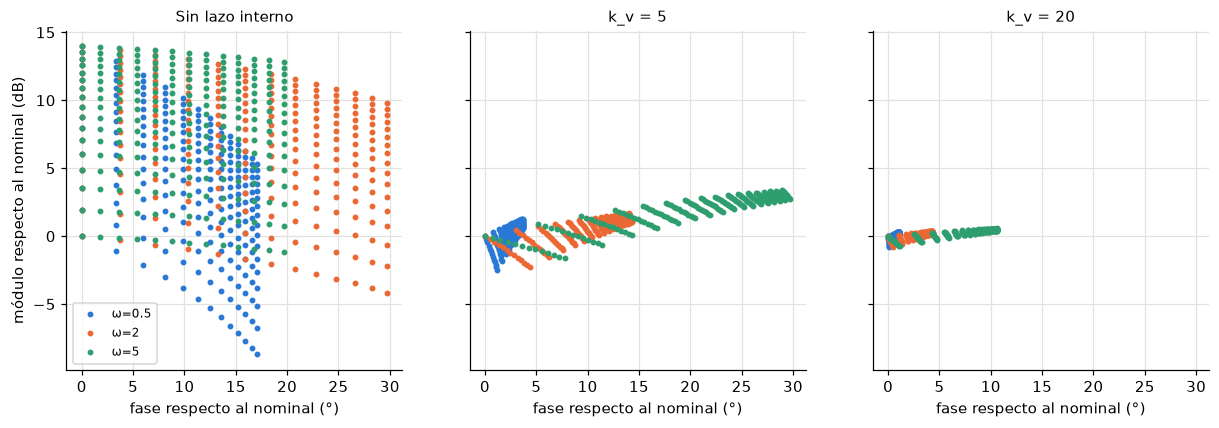

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13.4, 4), sharex=True, sharey=True)
for ax, (kvv, t) in zip(axs, ((0, "Sin lazo interno"), (5, "k_v = 5"), (20, "k_v = 20"))):
    for w, c in ((0.5, AZUL), (2, NARANJA), (5, VERDE)):
        z = np.array([P1c(w, K, a, kvv) for K in KS for a in AS]); rel = z/P1c(w, 1, 1, kvv)
        ax.scatter(np.degrees(np.angle(rel)), db(rel), s=8, color=c, label=f"ω={w:g}")
    ax.set_title(t, fontsize=10); ax.set_xlabel("fase respecto al nominal (°)")
axs[0].set_ylabel("módulo respecto al nominal (dB)"); axs[0].legend(fontsize=8); plt.show()

## 3. Diseño del lazo externo: solo una ganancia

Con el lazo interno puesto (discreto, $T_s=0.04$), repetimos la comprobación del Paso 8 sobre $P_1(z)$ con $G=k$:

In [5]:
def disc(K, a):
    A = np.array([[0, 1], [0, -a]]); B = np.array([[0], [K]])
    sd = signal.cont2discrete((A, B, np.eye(2), np.zeros((2, 1))), Ts, method="zoh"); return sd[0], sd[1]

def P1z(K, a, kvv, W):
    """x1/v_ref del lazo interno cerrado con u = kv (v_ref - x2), a z = e^{jωTs}."""
    Ad, Bd = disc(K, a); Acl = Ad - Bd @ np.array([[0, kvv]]); Bcl = Bd*kvv
    return np.array([(np.array([[1, 0]]) @ np.linalg.solve(np.exp(1j*w*Ts)*np.eye(2) - Acl, Bcl))[0, 0] for w in np.atleast_1d(W)])

def rho_interno(K, a, kvv):
    """Polo del lazo interno (primer orden en x2): z = Ad[1,1] - Bd[1]·kv."""
    Ad, Bd = disc(K, a); return abs(Ad[1, 1] - Bd[1, 0]*kvv)

def rho_total(K, a, kvv, kk):
    """Mayor |z| del lazo cerrado completo con u = -k·kv·x1 - kv·x2."""
    Ad, Bd = disc(K, a); return np.abs(np.linalg.eigvals(Ad - Bd @ np.array([[kk*kvv, kvv]]))).max()

W = np.logspace(-2, np.log10(0.97*np.pi/Ts), 250)
fam = np.array([P1z(K, a, kv, W) for K in KS for a in AS]); p0 = P1z(1, 1, kv, W)    # (221, nW)
def malas(kk):
    mal = []
    for i, w in enumerate(W):
        a_, b_, c_ = spec_ok(w, np.array(kk*p0[i]), fam[:, i]/p0[i])
        if not (a_ and b_ and c_): mal.append(round(float(w), 2))
    return mal

for kk in (1.5, 2, 3, 4, 6):
    m = malas(kk); print(f"k = {kk:<4}: {'cumple en todo el barrido' if not m else 'incumple en ω = ' + str(m[:5]) + (' …' if len(m) > 5 else '')}")

k = 1.5 : incumple en ω = [0.29, 0.3, 0.31, 0.33, 0.34] …
k = 2   : incumple en ω = [0.39, 0.4, 0.42, 0.43, 0.45] …
k = 3   : cumple en todo el barrido
k = 4   : cumple en todo el barrido
k = 6   : cumple en todo el barrido


Basta cualquier $k\ge3$; se elige **$k=4$**, el centro razonable. Con $k$ muy baja falla el rechazo de perturbación (manda la ganancia del lazo externo a baja frecuencia).

## 4. El mismo diseño es una realimentación de estados

$u=k_v\big(k(r_f-x_1)-x_2\big)=-k_1x_1-k_2x_2+k\,k_v\,r_f$ con $k_1=kk_v=20$ y $k_2=k_v=5$. La lectura QFT añade lo que la ubicación de polos no da: cómo se reparte la incertidumbre y qué especificación manda en cada lazo.

## 5. Verificación del diseño discreto

In [6]:
L = k*fam; T = np.abs(L/(1 + L)); S = 1/np.abs(1 + L)
nF_, dF_, _ = signal.cont2discrete(([1.2], [1, 1.2]), Ts, method="bilinear")
print(f"max|T|                    = {db(T.max()):.2f} dB  (límite 1.58)")
print(f"max|S| ω≤0.5 / 0.5<ω≤1    = {S[:, W<=0.5].max():.3f} / {S[:, (W>0.5)&(W<=1)].max():.3f}  (límites 0.3 / 0.5)")
print(f"|T| para ω≥30             ≤ {db(T[:, W>=30].max()):.1f} dB")
print(f"polos del lazo cerrado completo: max|z| = {max(rho_total(K, a, kv, k) for K in KS for a in AS):.3f}   (diapositivas: 0.883)")
print(f"polo del lazo interno: max|z| = {max(rho_interno(K, a, kv) for K in KS for a in AS):.3f}")
print(f"ganancia de u por error de posición: k·kv = {k*kv:.0f} (lazo único: 37.8)")

max|T|                    = 0.08 dB  (límite 1.58)
max|S| ω≤0.5 / 0.5<ω≤1    = 0.192 / 0.388  (límites 0.3 / 0.5)
|T| para ω≥30             ≤ -18.3 dB
polos del lazo cerrado completo: max|z| = 0.883   (diapositivas: 0.883)
polo del lazo interno: max|z| = 0.765
ganancia de u por error de posición: k·kv = 20 (lazo único: 37.8)


## 6. En discreto: el lazo interno tiene un límite de $k_v$

El lazo interno es de primer orden con ganancia $Kk_v$. Es estable con ZOH si $K_{\max}\,k_v\,T_s<2$. Con $T_s=0.04$: $k_v<10$. Lo comprobamos con la familia completa:

In [7]:
print(f"{'k_v':>5} {'max |z|':>9}  estable")
for kvv in (2, 5, 8, 9.5, 10, 10.5, 15):
    r_ = max(rho_interno(K, a, kvv) for K in (1, 5) for a in (1, 3)); print(f"{kvv:>5} {r_:>9.3f}  {r_ < 0.9999}")
print(f"\nlímite teórico: k_v < 2/(K_max·Ts) = {2/(5*Ts):.1f}")

  k_v   max |z|  estable
    2     0.882  True
    5     0.765  True
    8     0.647  True
  9.5     0.904  True
   10     1.000  True
 10.5     1.098  False
   15     1.980  False

límite teórico: k_v < 2/(K_max·Ts) = 10.0


$k_v=5$ queda a la mitad del límite. Un lazo interno inestable **no** lo detecta la comprobación de bounds (solo ve $|T|$ y $|S|$): hay que mirar los polos de la familia.

## 7. Respuesta temporal: la familia se cierra

   (K,a) |        lazo único        |         cascada         
         |    t90 (s)     pico u   |    t90 (s)     pico u
  (1, 1) |       1.76       2.41   |       2.20       2.59
  (5, 1) |       1.92       1.93   |       2.20       0.89
  (1, 3) |       2.76       2.43   |       2.36       2.93
  (5, 3) |       2.04       1.94   |       2.24       0.91


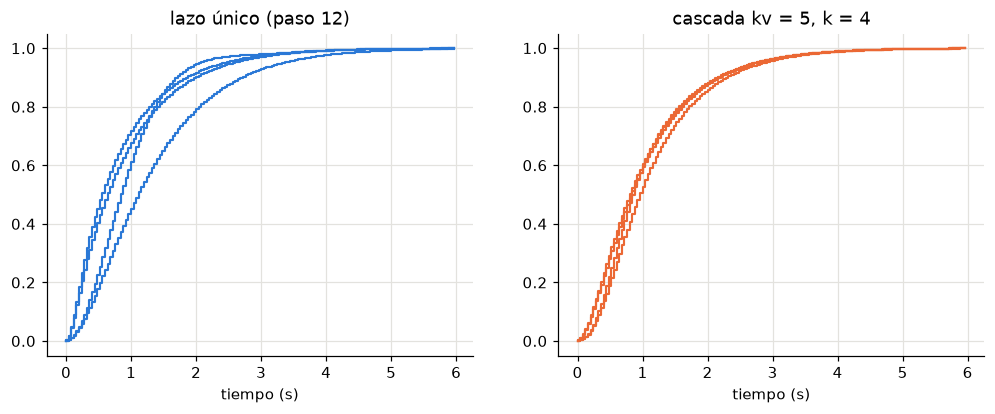

In [8]:
N = int(6/Ts); tt = np.arange(N)*Ts
nG, dG, _ = signal.cont2discrete(([5.2*28/2.6, 5.2*28], [1, 28]), Ts, method="bilinear"); nG = nG.ravel()
def sim_unico(K, a):
    Ad, Bd = disc(K, a); x = np.zeros((2, 1)); y = np.zeros(N); u = np.zeros(N); rfp = rp = ep = up = 0.0
    for i in range(N):
        yk = x[0, 0]; rf = -dF[1]*rfp + nF[0]*(1 + rp); e = rf - yk; un = -dG[1]*up + nG[0]*e + nG[1]*ep
        y[i] = yk; u[i] = un; x = Ad @ x + Bd*un; rfp, rp, ep, up = rf, 1, e, un
    return y, u
def sim_cascada(K, a, nz=0.0, seed=0):
    Ad, Bd = disc(K, a); x = np.zeros((2, 1)); y = np.zeros(N); u = np.zeros(N); rfp = rp = 0.0; rng = np.random.default_rng(seed)
    for i in range(N):
        rf = -dF[1]*rfp + nF[0]*(1 + rp); un = kv*(k*(rf - x[0, 0]) - (x[1, 0] + nz*rng.standard_normal()))
        y[i] = x[0, 0]; u[i] = un; x = Ad @ x + Bd*un; rfp, rp = rf, 1
    return y, u

print(f"{'(K,a)':>8} | {'lazo único':^24} | {'cascada':^24}")
print(f"{'':>8} | {'t90 (s)':>10} {'pico u':>10}   | {'t90 (s)':>10} {'pico u':>10}")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for K, a in ((1, 1), (5, 1), (1, 3), (5, 3)):
    ys, us = sim_unico(K, a); yc, uc = sim_cascada(K, a)
    print(f"{str((K, a)):>8} | {tt[np.argmax(ys >= 0.9)]:>10.2f} {abs(us).max():>10.2f}   | {tt[np.argmax(yc >= 0.9)]:>10.2f} {abs(uc).max():>10.2f}")
    axs[0].step(tt, ys, color=AZUL, lw=1.4); axs[1].step(tt, yc, color=NARANJA, lw=1.4)
axs[0].set_title("lazo único (paso 12)"); axs[1].set_title("cascada kv = 5, k = 4")
for a in axs: a.set_xlabel("tiempo (s)")
plt.show()

Tiempo de subida al 90 %: lazo único de 1.76 a 2.76 s; cascada de 2.20 a 2.36 s. **La dispersión baja de 1.0 s a 0.16 s.**

## 8. El precio: ruido en la velocidad

In [9]:
for K, a in ((5, 1), (1, 3)):
    y_, u_ = sim_cascada(K, a, nz=0.05); y0_, u0_ = sim_cascada(K, a)
    m = tt >= 3
    print(f"(K,a)=({K},{a}): σ(u) con ruido = {u_[m].std():.2f} (sin ruido {u0_[m].std():.2f});  σ(y-1) = {(y_[m]-1).std():.4f} (sin ruido {(y0_[m]-1).std():.4f})")

(K,a)=(5,1): σ(u) con ruido = 0.35 (sin ruido 0.00);  σ(y-1) = 0.0110 (sin ruido 0.0100)
(K,a)=(1,3): σ(u) con ruido = 0.26 (sin ruido 0.02);  σ(y-1) = 0.0126 (sin ruido 0.0118)


El ruido de la velocidad pasa casi entero al mando ($k_v=5$) pero apenas afecta a $y$ (el integrador lo filtra): hay que filtrar $x_2$ si el actuador es sensible.

## 9. Más allá: MIMO $2\times2$ y referencias

Con dos entradas y dos salidas, QFT descompone el problema en varios MISO en secuencia (Horowitz, 1979): se diseña primero el lazo diagonal 1, luego el 2 con el 1 cerrado, etc. La cascada es el caso más sencillo de «lazo cerrado dentro de otro» y por eso se estudia antes.

## 10. Ejercicio del Paso 14

1. ¿Qué $k_v$ máximo admite el lazo interno si $T_s=0.02$ s? 2. ¿Y con $T_s=0.1$? 3. ¿Cuánto valen $k_1$ y $k_2$ de la realimentación de estados con $k_v=10$, $k=3$?

**Tu turno.**

In [10]:
# 1-2) kv < 2/(Kmax Ts)   3) k1 = k kv, k2 = kv
# escribe aquí tu código

In [11]:
def kv_max(Ts_):
    """Mayor kv con el lazo interno estable en toda la familia (bisección sobre el polo z = Ad[1,1] - Bd[1]·kv)."""
    def polo(K_, a_, kvv):
        Ad, Bd = signal.cont2discrete((np.array([[0, 1], [0, -a_]]), np.array([[0], [K_]]), np.eye(2), np.zeros((2, 1))), Ts_, method="zoh")[:2]
        return abs(Ad[1, 1] - Bd[1, 0]*kvv)
    lo, hi = 0.1, 100.0
    for _ in range(60):
        mid = (lo + hi)/2
        lo, hi = (mid, hi) if all(polo(K_, a_, mid) < 1 for K_ in (1, 5) for a_ in (1, 3)) else (lo, mid)
    return hi
for Ts_ in (0.02, 0.1):
    print(f"Ts = {Ts_}: kv < 2/(5·{Ts_}) = {2/(5*Ts_):.1f}   (búsqueda numérica con la familia: {kv_max(Ts_):.1f})")
print(f"3) k1 = k·kv = {3*10}, k2 = kv = {10}.  Ojo: con Ts = 0.04 ese kv = 10 está EN el límite (Kmax·kv·Ts = 2): no es una elección válida con ese periodo.")

Ts = 0.02: kv < 2/(5·0.02) = 20.0   (búsqueda numérica con la familia: 20.0)
Ts = 0.1: kv < 2/(5·0.1) = 4.0   (búsqueda numérica con la familia: 4.0)
3) k1 = k·kv = 30, k2 = kv = 10.  Ojo: con Ts = 0.04 ese kv = 10 está EN el límite (Kmax·kv·Ts = 2): no es una elección válida con ese periodo.


## 11. Resumen

- Lazo interno sobre $x_2$ ⇒ la incertidumbre queda dentro; el template del lazo externo se encoge (18.1 → 4.0 dB en $\omega=2$).
- Lazo externo: **una ganancia** $k$; todo el diseño equivale a realimentación de estados $u=-k_1x_1-k_2x_2$.
- Límite en discreto: $K_{\max}k_vT_s<2$. Precio: ruido de $x_2$ en el mando.